<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/15_Federated_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 15 — Deep Learning on Unseen Data: Introducing Federated Learning

**Grokking Deep Learning** (Andrew W. Trask) — Tugas 2: *Code Reproduction + Theoretical Deep-Dive*

Deep learning membutuhkan data, tetapi data sensitif (email, rekam medis, ketikan keyboard) sering tidak boleh keluar dari perangkat pemiliknya. **Federated learning** membalik arah: *modelnya* yang dikirim ke data, dilatih di sana, lalu hanya pembaruan model yang dikembalikan. Bab ini juga menunjukkan bahwa pembaruan itu sendiri bisa membocorkan data, dan bagaimana *secure aggregation* serta *homomorphic encryption* menanganinya.

**Isi notebook:**
1. Masalah privasi dalam deep learning
2. Deteksi spam (model dasar yang dilatih terpusat) dengan framework Bab 13
3. Federated learning: tiga pengguna melatih, server merata-ratakan model
4. **Meretas** federated learning: kata-kata email bocor dari pembaruan bobot
5. *Secure aggregation*: menjumlahkan pembaruan banyak pengguna
6. *Homomorphic encryption* (Paillier, implementasi mainan) dan federated learning terenkripsi
7. Tanya-jawab konsep, latihan, rangkuman

> **Catatan data:** buku memakai korpus email Enron (`spam.txt`, `ham.txt`). `load_emails()` mencoba mengunduhnya dan, bila gagal, memakai **email sintetis** (kata spam/ham/umum dibangkitkan acak). Sumber aktual dicetak pada output. Enkripsi Paillier di sini memakai kunci **256-bit untuk demonstrasi** (tidak aman; praktik nyata ≥ 2048-bit) dan diimplementasikan sendiri tanpa pustaka tambahan.

## 1. Framework (dari Bab 13)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Tensor(object):
    def __init__(self, data, autograd=False, creators=None, creation_op=None, id=None):
        self.data = np.array(data)
        self.autograd = autograd
        self.grad = None
        self.id = np.random.randint(0, 10**9) if id is None else id
        self.creators = creators
        self.creation_op = creation_op
        self.children = {}
        if creators is not None:
            for c in creators:
                c.children[self.id] = c.children.get(self.id, 0) + 1

    def all_children_grads_accounted_for(self):
        return all(cnt == 0 for cnt in self.children.values())

    def backward(self, grad=None, grad_origin=None):
        if not self.autograd: return
        if grad is None: grad = Tensor(np.ones_like(self.data))
        if grad_origin is not None:
            if self.children[grad_origin.id] == 0:
                raise Exception("cannot backprop more than once")
            self.children[grad_origin.id] -= 1
        self.grad = grad if self.grad is None else Tensor(self.grad.data + grad.data)
        assert grad.autograd == False
        if self.creators is not None and (self.all_children_grads_accounted_for() or grad_origin is None):
            op = self.creation_op; c = self.creators
            if op == "add":
                c[0].backward(self.grad, self); c[1].backward(self.grad, self)
            elif op == "sub":
                c[0].backward(Tensor(self.grad.data), self); c[1].backward(Tensor((-self.grad).data), self)
            elif op == "mul":
                c[0].backward(self.grad * c[1], self); c[1].backward(self.grad * c[0], self)
            elif op == "neg":
                c[0].backward((-self.grad), self)
            elif op == "mm":
                c[0].backward(self.grad.mm(c[1].transpose()), self)
                c[1].backward(self.grad.transpose().mm(c[0]).transpose(), self)
            elif op == "transpose":
                c[0].backward(self.grad.transpose(), self)
            elif op.startswith("sum_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.expand(dim, c[0].data.shape[dim]), self)
            elif op.startswith("expand_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.sum(dim), self)
            elif op == "sigmoid":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (self * (ones - self)), self)
            elif op == "tanh":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (ones - (self * self)), self)
            elif op == "index_select":
                new_grad = np.zeros_like(c[0].data)
                idx = self.index_select_indices.data.flatten()
                g = self.grad.data.reshape(len(idx), -1)
                for i in range(len(idx)): new_grad[idx[i]] += g[i]
                c[0].backward(Tensor(new_grad), self)
            elif op == "cross_entropy":
                dx = (self.softmax_output - self.target_dist) / len(self.target_dist)   # rata-rata atas batch (buku: tanpa pembagian)
                c[0].backward(Tensor(dx), self)

    def _bin(self, other, op, fn):
        if self.autograd and other.autograd:
            return Tensor(fn(self.data, other.data), autograd=True, creators=[self, other], creation_op=op)
        return Tensor(fn(self.data, other.data))
    def __add__(self, other): return self._bin(other, "add", lambda a, b: a + b)
    def __sub__(self, other): return self._bin(other, "sub", lambda a, b: a - b)
    def __mul__(self, other): return self._bin(other, "mul", lambda a, b: a * b)
    def mm(self, x):          return self._bin(x, "mm", lambda a, b: a.dot(b))
    def __neg__(self):
        if self.autograd: return Tensor(self.data * -1, autograd=True, creators=[self], creation_op="neg")
        return Tensor(self.data * -1)
    def sum(self, dim):
        if self.autograd: return Tensor(self.data.sum(dim), autograd=True, creators=[self], creation_op="sum_" + str(dim))
        return Tensor(self.data.sum(dim))
    def expand(self, dim, copies):
        trans_cmd = list(range(0, len(self.data.shape))); trans_cmd.insert(dim, len(self.data.shape))
        new_data = self.data.repeat(copies).reshape(list(self.data.shape) + [copies]).transpose(trans_cmd)
        if self.autograd: return Tensor(new_data, autograd=True, creators=[self], creation_op="expand_" + str(dim))
        return Tensor(new_data)
    def transpose(self):
        if self.autograd: return Tensor(self.data.transpose(), autograd=True, creators=[self], creation_op="transpose")
        return Tensor(self.data.transpose())
    def sigmoid(self):
        if self.autograd: return Tensor(1 / (1 + np.exp(-self.data)), autograd=True, creators=[self], creation_op="sigmoid")
        return Tensor(1 / (1 + np.exp(-self.data)))
    def tanh(self):
        if self.autograd: return Tensor(np.tanh(self.data), autograd=True, creators=[self], creation_op="tanh")
        return Tensor(np.tanh(self.data))
    def index_select(self, indices):
        if self.autograd:
            new = Tensor(self.data[indices.data], autograd=True, creators=[self], creation_op="index_select")
            new.index_select_indices = indices
            return new
        return Tensor(self.data[indices.data])
    def cross_entropy(self, target_indices):
        temp = np.exp(self.data - self.data.max(axis=-1, keepdims=True))
        softmax_output = temp / np.sum(temp, axis=len(self.data.shape) - 1, keepdims=True)
        t = target_indices.data.flatten()
        p = softmax_output.reshape(len(t), -1)
        target_dist = np.eye(p.shape[1])[t]
        loss = -(np.log(p) * target_dist).sum(1).mean()
        if self.autograd:
            out = Tensor(loss, autograd=True, creators=[self], creation_op="cross_entropy")
            out.softmax_output = softmax_output; out.target_dist = target_dist
            return out
        return Tensor(loss)
    def __repr__(self): return str(self.data.__repr__())
    def __str__(self):  return str(self.data.__str__())

In [2]:
class SGD(object):
    def __init__(self, parameters, alpha=0.1):
        self.parameters = parameters; self.alpha = alpha
    def zero(self):
        for p in self.parameters: p.grad.data *= 0
    def step(self, zero=True):
        for p in self.parameters:
            p.data -= p.grad.data * self.alpha
            if zero: p.grad.data *= 0

In [3]:
class Layer(object):
    def __init__(self): self.parameters = list()
    def get_parameters(self): return self.parameters

class Linear(Layer):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()
        W = np.random.randn(n_inputs, n_outputs) * np.sqrt(2.0 / n_inputs)
        self.weight = Tensor(W, autograd=True)
        self.bias = Tensor(np.zeros(n_outputs), autograd=True)
        self.parameters += [self.weight, self.bias]
    def forward(self, input):
        return input.mm(self.weight) + self.bias.expand(0, len(input.data))

class Sequential(Layer):
    def __init__(self, layers=list()):
        super().__init__(); self.layers = layers
    def add(self, layer): self.layers.append(layer)
    def forward(self, input):
        for layer in self.layers: input = layer.forward(input)
        return input
    def get_parameters(self):
        params = list()
        for l in self.layers: params += l.get_parameters()
        return params

class MSELoss(Layer):
    def forward(self, pred, target): return ((pred - target) * (pred - target)).sum(0)

class Tanh(Layer):
    def forward(self, input): return input.tanh()
class Sigmoid(Layer):
    def forward(self, input): return input.sigmoid()

In [4]:
class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.vocab_size = vocab_size; self.dim = dim
        weight = (np.random.rand(vocab_size, dim) - 0.5) / dim
        self.weight = Tensor(weight, autograd=True)
        self.parameters.append(self.weight)
    def forward(self, input): return self.weight.index_select(input)

class CrossEntropyLoss(object):
    def forward(self, input, target): return input.cross_entropy(target)

## 2. Data email dan model deteksi spam

In [5]:
import copy, random, math, time, urllib.request
import matplotlib.pyplot as plt

def synthetic_emails(n_per_class=1800, seed=0):
    rng = np.random.RandomState(seed)
    spam_w = ("free winner cash prize offer click now limited credit loan cheap pills discount urgent bonus guarantee "
              "million lottery claim congratulations bargain deal buy order viagra casino subscribe").split()
    ham_w = ("meeting report schedule project deadline team review budget lunch client thanks regards attached "
             "tomorrow agenda draft contract invoice update call office manager proposal presentation conference "
             "document revised sprint").split()
    com_w = "the a to of and in for is on that with this you we it be will are have not from at as by please".split()
    mails = []
    for label in (1, 0):
        for _ in range(n_per_class):
            L = rng.randint(25, 55); ps, ph = (0.30, 0.15) if label else (0.02, 0.35)
            words = []
            for _ in range(L):
                r = rng.rand()
                words.append(spam_w[rng.randint(len(spam_w))] if r < ps else
                             ham_w[rng.randint(len(ham_w))] if r < ps + ph else com_w[rng.randint(len(com_w))])
            mails.append((words, label))
    rng.shuffle(mails)
    return mails

def load_emails(limit=1800):
    base = "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/master/"
    try:
        sp = urllib.request.urlopen(base + "spam.txt", timeout=8).read().decode().splitlines()[:limit]
        hm = urllib.request.urlopen(base + "ham.txt", timeout=8).read().decode().splitlines()[:limit]
        mails = [(l.split(" "), 1) for l in sp] + [(l.split(" "), 0) for l in hm]
        random.Random(0).shuffle(mails)
        return mails, "Enron asli (spam.txt / ham.txt)"
    except Exception:
        return synthetic_emails(), "SINTETIS (unduhan gagal / offline)"

mails, source = load_emails()
print("Sumber data:", source, "| jumlah email:", len(mails), "| proporsi spam: %.2f" % np.mean([y for _, y in mails]))
print("Contoh email  :", " ".join(mails[0][0][:14]), "... -> label", mails[0][1])

vocab = sorted(set(w for words, _ in mails for w in words)) + ["<unk>"]
w2i = {w: i for i, w in enumerate(vocab)}
maxlen = 60
def encode(words):
    ids = [w2i[w] for w in words][:maxlen]
    return ids + [w2i["<unk>"]] * (maxlen - len(ids))       # padding memakai <unk>
X = np.array([encode(w) for w, _ in mails]); Y = np.array([[y] for _, y in mails])
n_test = 400
train_data, train_target = X[:-n_test], Y[:-n_test]
test_data, test_target = X[-n_test:], Y[-n_test:]
print("Ukuran kosakata:", len(vocab), "| data latih:", len(train_data), "| data uji:", len(test_data))

Sumber data: SINTETIS (unduhan gagal / offline) | jumlah email: 3600 | proporsi spam: 0.50
Contoh email  : cash on have update with you buy urgent that order bonus this at have ... -> label 1
Ukuran kosakata: 81 | data latih: 3200 | data uji: 400


In [6]:
bs = 100
def train(model, input_data, target_data, iterations=1, alpha=0.01, verbose=False):
    criterion = MSELoss()
    optim = SGD(parameters=model.get_parameters(), alpha=alpha)
    n_batches = int(len(input_data) / bs)
    for it in range(iterations):
        iter_loss = 0
        for b_i in range(n_batches):
            model.weight.data[w2i['<unk>']] *= 0            # token padding dijaga tetap 0
            inp = Tensor(input_data[b_i*bs:(b_i+1)*bs], autograd=True)
            tgt = Tensor(target_data[b_i*bs:(b_i+1)*bs], autograd=True)
            pred = model.forward(inp).sum(1).sigmoid()
            loss = criterion.forward(pred, tgt)
            loss.backward(); optim.step()
            iter_loss += loss.data[0] / bs
        if verbose: print("  epoch %d loss=%.4f" % (it, iter_loss / n_batches))
    return model

def test(model, test_input, test_output):
    model.weight.data[w2i['<unk>']] *= 0
    pred = model.forward(Tensor(test_input, autograd=True)).sum(1).sigmoid()
    return float(((pred.data > 0.5) == test_output).mean())

np.random.seed(0)
model = Embedding(vocab_size=len(vocab), dim=1); model.weight.data *= 0
print("Akurasi sebelum latihan: %.3f" % test(model, test_data, test_target))
train(model, train_data, train_target, iterations=3, verbose=True)
print("Akurasi uji model terpusat (data digabung di satu tempat): %.3f" % test(model, test_data, test_target))

Akurasi sebelum latihan: 0.485
  epoch 0 loss=0.0744
  epoch 1 loss=0.0141
  epoch 2 loss=0.0107
Akurasi uji model terpusat (data digabung di satu tempat): 0.998


## 3. Federated learning

Tiga pengguna (Bob, Alice, Sue) masing-masing memegang sepertiga data latih **di perangkat mereka**. Pada setiap ronde: (1) server mengirim model ke tiap pengguna, (2) tiap pengguna melatihnya pada data lokal, (3) pengguna mengirim kembali model hasil latihan, (4) server **merata-ratakan** bobotnya. Data mentah tidak pernah meninggalkan pengguna.

In [7]:
third = len(train_data) // 3
bob   = (train_data[0:third],         train_target[0:third])
alice = (train_data[third:2*third],   train_target[third:2*third])
sue   = (train_data[2*third:3*third], train_target[2*third:3*third])

def clone(m):
    c = Embedding(vocab_size=len(vocab), dim=1); c.weight.data = m.weight.data.copy(); return c

np.random.seed(0)
fed_model = Embedding(vocab_size=len(vocab), dim=1); fed_model.weight.data *= 0
fed_acc = []
for r in range(3):
    bob_model   = train(clone(fed_model), bob[0],   bob[1],   iterations=1)
    alice_model = train(clone(fed_model), alice[0], alice[1], iterations=1)
    sue_model   = train(clone(fed_model), sue[0],   sue[1],   iterations=1)
    fed_model.weight.data = (bob_model.weight.data + alice_model.weight.data + sue_model.weight.data) / 3
    fed_acc.append(test(fed_model, test_data, test_target))
    print("Ronde %d  | akurasi uji model gabungan: %.3f" % (r + 1, fed_acc[-1]))
print("\nTerpusat: %.3f | Federated (3 ronde): %.3f" % (test(model, test_data, test_target), fed_acc[-1]))

Ronde 1  | akurasi uji model gabungan: 0.993
Ronde 2  | akurasi uji model gabungan: 0.998
Ronde 3  | akurasi uji model gabungan: 0.998

Terpusat: 0.998 | Federated (3 ronde): 0.998


## 4. Meretas federated learning

Walau data tidak dikirim, **pembaruan bobot bocor**: hanya bobot kata yang *muncul* di data Bob yang berubah dari nol. Siapa pun yang melihat model hasil latihan Bob (mis. server yang jahat) dapat membaca kata-kata dalam email Bob. Demo: Bob melatih model dengan **satu email** saja.

In [8]:
np.random.seed(0)
base = Embedding(vocab_size=len(vocab), dim=1); base.weight.data *= 0
bob_one = (train_data[0:1], train_target[0:1])
bob_update = clone(base)
# pada batch 1 email: n_batches = 1/bs = 0 -> gunakan bs=1 sementara
bs_old, bs = bs, 1
train(bob_update, bob_one[0], bob_one[1], iterations=1)
bs = bs_old

changed = np.where(bob_update.weight.data.flatten() != 0)[0]
leaked = sorted(set(vocab[i] for i in changed if vocab[i] != "<unk>"))   # <unk> hanya padding
real = sorted(set(vocab[i] for i in bob_one[0][0] if vocab[i] != "<unk>"))
print("Kata di email asli Bob :", real)
print("Kata yang bocor dari update:", leaked)
print("Semua kata email Bob berhasil direkonstruksi:", set(real) == set(leaked))

Kata di email asli Bob : ['are', 'at', 'be', 'bonus', 'buy', 'cash', 'claim', 'guarantee', 'have', 'it', 'meeting', 'not', 'of', 'offer', 'office', 'on', 'order', 'that', 'this', 'to', 'tomorrow', 'update', 'urgent', 'will', 'with', 'you']
Kata yang bocor dari update: ['are', 'at', 'be', 'bonus', 'buy', 'cash', 'claim', 'guarantee', 'have', 'it', 'meeting', 'not', 'of', 'offer', 'office', 'on', 'order', 'that', 'this', 'to', 'tomorrow', 'update', 'urgent', 'will', 'with', 'you']
Semua kata email Bob berhasil direkonstruksi: True


## 5. *Secure aggregation*

Jika server hanya menerima **jumlah** pembaruan dari banyak pengguna, ia tidak bisa lagi menghubungkan kata tertentu dengan satu pengguna: kata yang muncul mungkin berasal dari siapa pun, apalagi kata umum yang dipakai semua orang. Syaratnya: jumlah pengguna cukup besar, dan penjumlahan dilakukan sebelum server melihat data (mis. lewat enkripsi atau pengacakan).

In [9]:
users = [(train_data[i:i+1], train_target[i:i+1]) for i in range(0, 30)]
updates = []; bs_old, bs = bs, 1
for u in users:
    m = train(clone(base), u[0], u[1], iterations=1); updates.append(m.weight.data.flatten().copy())
bs = bs_old
updates = np.array(updates)
aggregate = updates.sum(0)
per_user_unique = [int(((updates[u] != 0) & (np.delete(updates, u, 0) == 0).all(0)).sum()) for u in range(len(users))]
indiv = [int((np.delete(updates[u], w2i["<unk>"]) != 0).sum()) for u in range(len(users))]
print("Bila update dilihat satu per satu, tiap pengguna membocorkan rata-rata %.1f kata emailnya" % np.mean(indiv))
print("Kata yang HANYA muncul pada satu pengguna (dari 30): rata-rata %.1f per pengguna (kosakata sintetis kecil, jadi hampir semua kata dipakai banyak orang)" % np.mean(per_user_unique))
print("Kata berubah pada jumlah agregat 30 pengguna:", int((aggregate != 0).sum()), "dari", len(vocab))
print("Pada agregat, server tidak tahu pengguna mana yang memakai kata tertentu (hanya totalnya).")

Bila update dilihat satu per satu, tiap pengguna membocorkan rata-rata 27.9 kata emailnya
Kata yang HANYA muncul pada satu pengguna (dari 30): rata-rata 0.1 per pengguna (kosakata sintetis kecil, jadi hampir semua kata dipakai banyak orang)
Kata berubah pada jumlah agregat 30 pengguna: 81 dari 81
Pada agregat, server tidak tahu pengguna mana yang memakai kata tertentu (hanya totalnya).


## 6. *Homomorphic encryption* (Paillier)

Enkripsi homomorfik memungkinkan **menghitung pada data terenkripsi**. Skema Paillier bersifat *additively homomorphic*: `E(a) · E(b) mod n² = E(a + b)`, dan `E(a)^k = E(k·a)`. Maka server dapat menjumlahkan pembaruan terenkripsi tanpa pernah melihat isinya. Di bawah ini implementasi mainan (kunci 256-bit, hanya demonstrasi).

In [10]:
def is_prime(n, k=25):
    if n < 2: return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29):
        if n % p == 0: return n == p
    d, s = n - 1, 0
    while d % 2 == 0: d //= 2; s += 1
    for _ in range(k):
        a = random.randrange(2, n - 1); x = pow(a, d, n)
        if x in (1, n - 1): continue
        for _ in range(s - 1):
            x = pow(x, 2, n)
            if x == n - 1: break
        else: return False
    return True
def gen_prime(bits):
    while True:
        p = random.getrandbits(bits) | (1 << (bits - 1)) | 1
        if is_prime(p): return p

class Paillier:
    def __init__(self, bits=128):
        p = gen_prime(bits); q = gen_prime(bits)
        while q == p: q = gen_prime(bits)
        self.n = p * q; self.n2 = self.n ** 2
        self.lam = (p - 1) * (q - 1) // math.gcd(p - 1, q - 1)
        self.mu = pow(self.lam, -1, self.n)                  # untuk g = n + 1
    def encrypt(self, m):
        r = random.randrange(1, self.n)
        while math.gcd(r, self.n) != 1: r = random.randrange(1, self.n)
        return ((1 + (m % self.n) * self.n) * pow(r, self.n, self.n2)) % self.n2
    def decrypt(self, c):
        x = pow(c, self.lam, self.n2); m = ((x - 1) // self.n * self.mu) % self.n
        return m - self.n if m > self.n // 2 else m          # bilangan bertanda
    def add(self, c1, c2): return (c1 * c2) % self.n2
    def mul_const(self, c, k): return pow(c, k, self.n2)

random.seed(7)
he = Paillier(128)
x = he.encrypt(5); y = he.encrypt(3)
print("Ciphertext 5 (potongan):", str(x)[:40], "...")
print("Dekripsi E(5)+E(3)     :", he.decrypt(he.add(x, y)), "(harapan 8)")
print("Dekripsi E(5)*4        :", he.decrypt(he.mul_const(x, 4)), "(harapan 20)")
print("Dekripsi E(-7)+E(3)    :", he.decrypt(he.add(he.encrypt(-7), y)), "(harapan -4)")

Ciphertext 5 (potongan): 2074695091380349648098147430066907176774 ...
Dekripsi E(5)+E(3)     : 8 (harapan 8)
Dekripsi E(5)*4        : 20 (harapan 20)
Dekripsi E(-7)+E(3)    : -4 (harapan -4)


### Federated learning dengan enkripsi homomorfik

Bobot berupa bilangan pecahan, sehingga diubah menjadi bilangan bulat (*fixed point*, skala 10⁶) sebelum dienkripsi. Alur: tiap pengguna mengenkripsi pembaruannya dengan **kunci publik**; server **menjumlahkan** ciphertext (tidak bisa membacanya); hasil jumlah didekripsi oleh pemilik kunci privat, lalu dirata-ratakan.

In [11]:
SCALE = 10**6
K = min(len(vocab), 300)         # demo: hanya K bobot pertama yang dienkripsi (agar cepat)
def enc_vec(w):  return [he.encrypt(int(round(v * SCALE))) for v in w[:K]]

np.random.seed(0)
g_model = Embedding(vocab_size=len(vocab), dim=1); g_model.weight.data *= 0
t0 = time.time()
locals_ = [train(clone(g_model), d[0], d[1], iterations=1) for d in (bob, alice, sue)]
vecs = [m.weight.data.flatten() for m in locals_]
enc = [enc_vec(v) for v in vecs]                     # dikerjakan oleh tiap pengguna
enc_sum = [ (lambda cs: __import__("functools").reduce(he.add, cs))([e[j] for e in enc]) for j in range(K) ]   # dikerjakan SERVER
dec_avg = np.array([he.decrypt(c) / SCALE / 3 for c in enc_sum])    # dikerjakan pemilik kunci privat
plain_avg = np.mean([v[:K] for v in vecs], axis=0)
print("Waktu enkripsi+agregasi+dekripsi untuk %d bobot x 3 pengguna: %.1f s" % (K, time.time() - t0))
print("Selisih maksimum rata-rata terenkripsi vs biasa: %.2e" % np.abs(dec_avg - plain_avg).max())
print("Contoh ciphertext yang dilihat server (bukan angka bobot):", str(enc[0][0])[:30], "...")

Waktu enkripsi+agregasi+dekripsi untuk 81 bobot x 3 pengguna: 0.4 s
Selisih maksimum rata-rata terenkripsi vs biasa: 4.01e-07
Contoh ciphertext yang dilihat server (bukan angka bobot): 604653058136102091395875713636 ...


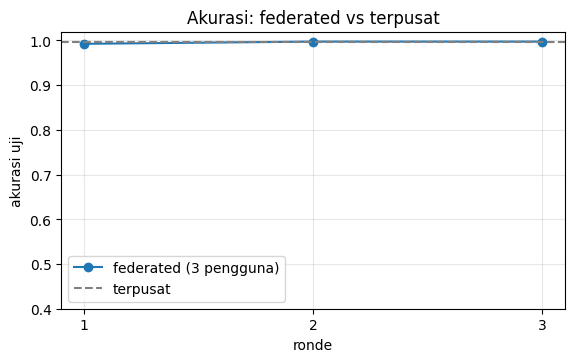

In [12]:
plt.figure(figsize=(6.5, 3.6))
plt.plot(range(1, 4), fed_acc, "o-", label="federated (3 pengguna)")
plt.axhline(test(model, test_data, test_target), color="gray", ls="--", label="terpusat")
plt.xticks([1, 2, 3]); plt.xlabel("ronde"); plt.ylabel("akurasi uji"); plt.ylim(0.4, 1.02); plt.legend(); plt.grid(alpha=.3)
plt.title("Akurasi: federated vs terpusat"); plt.show()

## 7. Tanya-jawab konsep

**1. Apa ide dasar federated learning?** Model dikirim ke data (bukan sebaliknya); pengguna melatih lokal dan hanya mengirim pembaruan; server menggabungkannya (mis. rata-rata bobot).

**2. Mengapa data tidak langsung dikumpulkan saja?** Alasan privasi, hukum (mis. regulasi data pribadi), ukuran data, dan kepercayaan; banyak data berharga (medis, pesan pribadi) tidak boleh keluar dari pemiliknya.

**3. Apakah federated learning otomatis menjaga privasi?** Tidak. Pembaruan bobot membocorkan informasi (demo: kata-kata email Bob direkonstruksi sempurna dari model yang dilatih satu email).

**4. Bagaimana secure aggregation membantu?** Server hanya melihat jumlah pembaruan banyak pengguna sehingga kontribusi individu menyamar; efektif bila pengguna banyak dan penjumlahan dilindungi.

**5. Apa itu homomorphic encryption?** Skema enkripsi yang mengizinkan operasi (di sini penjumlahan) langsung pada ciphertext; hasilnya, bila didekripsi, sama dengan operasi pada data asli. Paillier mendukung penjumlahan dan perkalian dengan konstanta.

**6. Apa kekurangannya?** Biaya komputasi dan ukuran data besar (lihat waktu pada output untuk hanya K bobot), serta hanya operasi tertentu yang didukung; bobot pecahan harus dikonversi ke bilangan bulat.

## 8. Latihan mandiri (dengan jawaban)

**Latihan 1.** Mengapa bobot `<unk>` direset ke 0 pada tiap batch? **Jawaban:** `<unk>` dipakai sebagai padding; bila bobotnya berubah, panjang email akan memengaruhi prediksi.

**Latihan 2.** Jika `E(a)·E(b) mod n² = E(a+b)`, bagaimana menghitung rata-rata terenkripsi 3 pengguna? **Jawaban:** Kalikan ketiga ciphertext (= jumlah), dekripsi, lalu bagi 3 (pembagian dilakukan setelah dekripsi, atau kalikan konstanta bila diizinkan).

**Latihan 3.** Mengapa agregasi dari 3 pengguna belum cukup aman? **Jawaban:** Dengan sedikit pengguna, kata yang hanya dimiliki seorang pengguna masih terlihat jelas dalam jumlah; privasi bertambah seiring jumlah pengguna dan keberagaman data.

**Latihan 4.** Mengapa kunci 256-bit pada demo tidak aman? **Jawaban:** Modulus sekecil itu dapat difaktorkan dengan mudah; praktik nyata memakai ≥ 2048-bit.

## Rangkuman

- **Federated learning** melatih model tanpa memusatkan data: model dikirim, dilatih lokal, dan dirata-ratakan. Pada demo (data sintetis yang mudah dipisahkan), akurasi uji gabungan sama dengan model terpusat (≈ 99,8%).
- Pembaruan bobot tetap **membocorkan** isi data (kata email Bob dapat direkonstruksi dari satu pembaruan).
- **Secure aggregation** dan **homomorphic encryption** mengurangi kebocoran; pada Paillier, jumlah ciphertext terdekripsi sama dengan jumlah data asli (selisih ≈ 1e-6 akibat pembulatan fixed point).
- Bab ini menutup buku: dari satu bobot (Bab 3) hingga framework, RNN/LSTM, dan pembelajaran yang menjaga privasi.